In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [ ]:
# ==========================================
# CONFIGURACIÓN DE LA SIMULACIÓN
# ==========================================
n_hectareas = 100  # Cambia este número por la cantidad de hectáreas que desees
anos = 10
ciclos_por_ano = 2  # Cada 6 meses (2 veces al año)
total_ciclos = anos * ciclos_por_ano  # 20 ciclos en total por hectárea

In [ ]:
# 1. Generar la cantidad de semillas ideal (x_i) para cada hectárea.
# Definimos que el ideal de cada terreno varíe, por ejemplo, entre 100 y 150 kg.
cantidad_x_hectarea = np.random.uniform(100, 150, size=n_hectareas)
cantidad_x_hectarea = np.round(cantidad_x_hectarea, 2)

# Lista para ir guardando las filas del dataset
registros = []

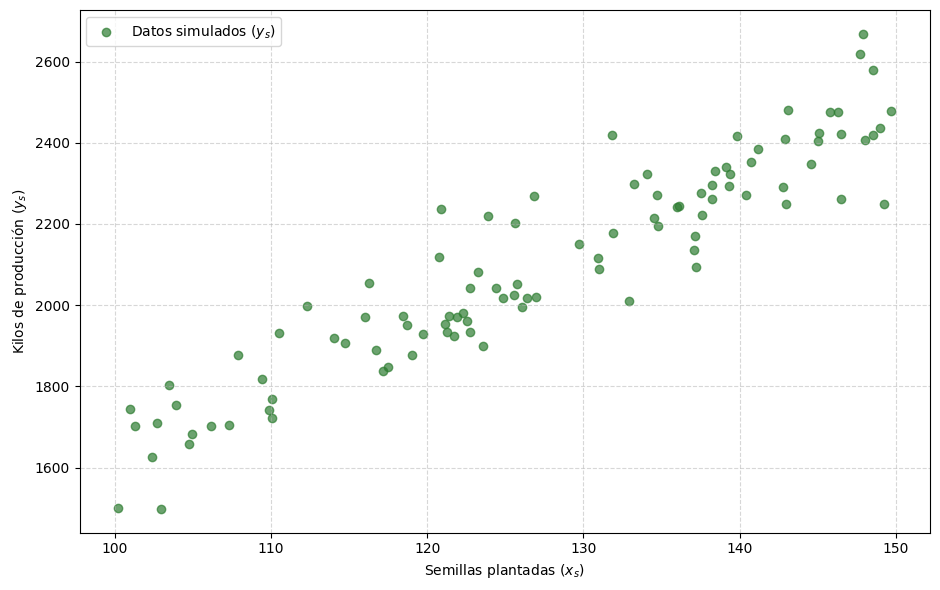

In [ ]:
np.random.seed(52)

# 1. Datos simulados con la ecuación y ruido
x_s = np.random.uniform(100, 150, size=n_hectareas)
ruido = np.random.normal(loc=10, scale=5, size=n_hectareas)
y_s = 15 * x_s * (1 + ruido / 100)

# 2. Líneas de referencia
x_linea = np.linspace(100, 150, 100)
y_base = 15 * x_linea                        # Sin considerar el efecto medio del ruido
y_esperado = 15 * x_linea * (1 + 10 / 100)  # Ecuación del valor esperado: y = 16.5x

# 3. Graficar
plt.figure(figsize=(9.5, 6))

# Datos observados
plt.scatter(x_s, y_s, color='#2e7d32', alpha=0.7, label='Datos simulados ($y_s$)')

#plt.title('Simulación de Producción: Datos, Modelo Puro y Modelo de Valor Esperado')
plt.xlabel('Semillas plantadas ($x_s$)')
plt.ylabel('Kilos de producción ($y_s$)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

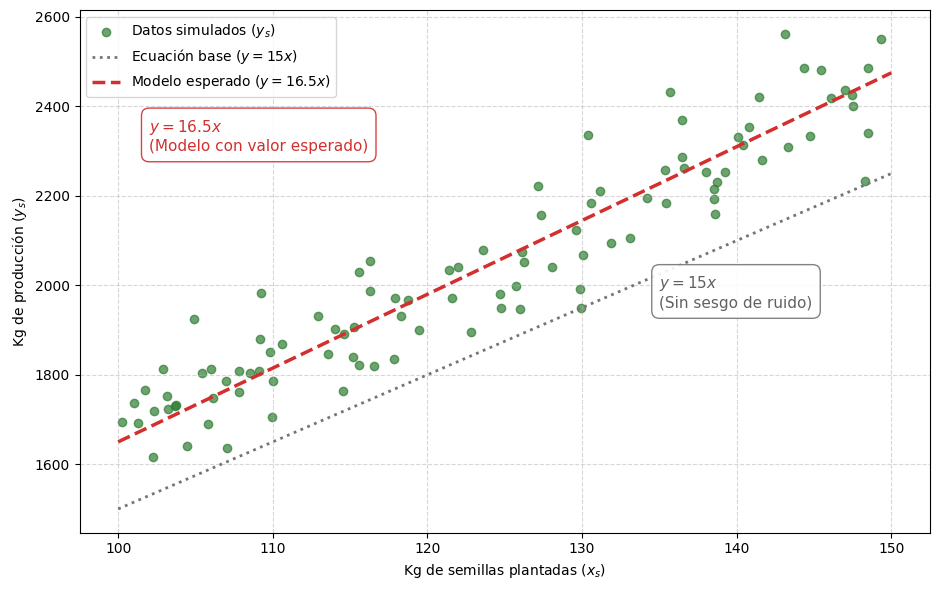

In [ ]:
np.random.seed(42)

# 1. Datos simulados con la ecuación y ruido
x_s = np.random.uniform(100, 150, size=n_hectareas)
ruido = np.random.normal(loc=10, scale=5, size=n_hectareas)
y_s = 15 * x_s * (1 + ruido / 100)

# 2. Líneas de referencia
x_linea = np.linspace(100, 150, 100)
y_base = 15 * x_linea                        # Sin considerar el efecto medio del ruido
y_esperado = 15 * x_linea * (1 + 10 / 100)  # Ecuación del valor esperado: y = 16.5x

# 3. Graficar
plt.figure(figsize=(9.5, 6))

# Datos observados
plt.scatter(x_s, y_s, color='#2e7d32', alpha=0.7, label='Datos simulados ($y_s$)')

# Línea base pura (y = 15x)
plt.plot(x_linea, y_base, color='#757575', linestyle=':', linewidth=2, label='Ecuación base ($y = 15x$)')

# Modelo de valor esperado (y = 16.5x)
plt.plot(x_linea, y_esperado, color='#d32f2f', linestyle='--', linewidth=2.5, label='Modelo esperado ($y = 16.5x$)')

# Anotaciones dentro del gráfico
plt.text(102, 2300, r'$y = 16.5x$' + '\n(Modelo con valor esperado)', fontsize=11, color='#d32f2f',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#d32f2f', alpha=0.9))

plt.text(135, 1950, r'$y = 15x$' + '\n(Sin sesgo de ruido)', fontsize=11, color='#616161',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='#757575', alpha=0.9))

#plt.title('Simulación de Producción: Datos, Modelo Puro y Modelo de Valor Esperado')
plt.xlabel('Kg de semillas plantadas ($x_s$)')
plt.ylabel('Kg de producción ($y_s$)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('c3_sim_produccion.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
cantidad_x_hectarea.shape

(100,)

In [ ]:
# ==========================================
# EJECUCIÓN DE LA SIMULACIÓN
# ==========================================
for i in range(n_hectareas):
    # Recuperamos la cantidad ideal de esta hectárea específica
    x_ideal = cantidad_x_hectarea[i]

    for ciclo in range(total_ciclos):
        # Calcular el año y el semestre actual
        ano_actual = 1 + (ciclo // 2)
        semestre_actual = 1 + (ciclo % 2)

        # Cada 6 meses plantamos x_s kg (variación entre 0.5 y 0.8 del ideal)
        factor_variacion = np.random.uniform(0.5, 0.8)
        x_s = x_ideal * factor_variacion
        x_s = np.round(x_s, 2)

        # Fórmula de producción con tu modificación de ruido en porcentaje: y = 15x + normal(10%, 5%)
        ruido = np.random.normal(loc=10, scale=5)
        y_s = 15 * x_s
        y_s = (1 + ruido / 100) * y_s

        # Guardar la información del ciclo actual (incluyendo la columna del ideal)
        registros.append({
            "Hectarea_ID": f"Hectarea_{i+1}",
            "Ideal_Hectarea_kg": x_ideal,
            "Ano": ano_actual,
            "Semestre": semestre_actual,
            "Semillas_Plantadas_x_kg": x_s,
            "Produccion_Obtenida_y_kg": y_s
        })

# 3. Crear el DataFrame final
df_simulacion = pd.DataFrame(registros)

# ==========================================
# VISUALIZACIÓN Y DESCARGA
# ==========================================
print(f"¡Simulación completada con éxito!")
print(f"Total de registros generados: {len(df_simulacion)} ({n_hectareas} hectáreas x {total_ciclos} semestres)\n")

¡Simulación completada con éxito!
Total de registros generados: 2000 (100 hectáreas x 20 semestres)



In [ ]:
# Mostrar las primeras filas del dataset
print("Primeras 5 filas del dataset:")
print(df_simulacion.head().to_markdown(index=False))

# Código opcional para descargar el archivo desde Colab a tu computadora
# Descomenta las siguientes dos líneas si deseas descargar el CSV directamente:
# from google.colab import files
# df_simulacion.to_csv('dataset_produccion_agricola.csv', index=False)

Primeras 5 filas del dataset:
| Hectarea_ID   |   Ideal_Hectarea_kg |   Ano |   Semestre |   Semillas_Plantadas_x_kg |   Produccion_Obtenida_y_kg |
|:--------------|--------------------:|------:|-----------:|--------------------------:|---------------------------:|
| Hectarea_1    |               111.5 |     1 |          1 |                     82.34 |                   1527.47  |
| Hectarea_1    |               111.5 |     1 |          2 |                     72.22 |                   1196.71  |
| Hectarea_1    |               111.5 |     2 |          1 |                     62.28 |                    982.638 |
| Hectarea_1    |               111.5 |     2 |          2 |                     56.56 |                    974.692 |
| Hectarea_1    |               111.5 |     3 |          1 |                     77.34 |                   1268.91  |


In [ ]:
# ==========================================
# 2. PREPARACIÓN DE DATOS (TRAIN/TEST SPLIT)
# ==========================================
# Posición ingenua: solo usamos 'x' para predecir 'y'
X = df_simulacion[['Semillas_Plantadas_x_kg']]
y = df_simulacion['Produccion_Obtenida_y_kg']

# Dividimos en 80% entrenamiento y 20% testeo
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==========================================
# 3. CONFIGURACIÓN Y ENTRENAMIENTO DE MODELOS
# ==========================================
# Nota: Al MLP le agregamos un escalador (StandardScaler) automáticamente
# porque las redes neuronales fallan gravemente si no se normalizan los datos.
modelos = {
    "Regresión Lineal": LinearRegression(),
    "Perceptrón Multicapa (MLP)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=3000)),
    "Random Forest": RandomForestRegressor(),
    "XGBoost": XGBRegressor()
}

# Diccionarios para guardar resultados
resultados_metricas = []
predicciones_modelos = {}

for nombre, modelo in modelos.items():
    # Entrenar el modelo
    modelo.fit(X_train, y_train)

    # Predecir en el conjunto de testeo
    y_pred = modelo.predict(X_test)
    predicciones_modelos[nombre] = y_pred

    # Calcular métricas
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    resultados_metricas.append({
        "Modelo": nombre,
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "R2 Score": round(r2, 4)
    })

# Mostrar tabla comparativa
df_metricas = pd.DataFrame(resultados_metricas)
print("### COMPARATIVA DE RENDIMIENTO EN EL TEST SET ###")
print(df_metricas.to_markdown(index=False))
print("\n" + "="*50 + "\n")

### COMPARATIVA DE RENDIMIENTO EN EL TEST SET ###
| Modelo                     |    RMSE |     MAE |   R2 Score |
|:---------------------------|--------:|--------:|-----------:|
| Regresión Lineal           | 64.029  | 51.3551 |     0.9394 |
| Perceptrón Multicapa (MLP) | 64.4202 | 51.7676 |     0.9386 |
| Random Forest              | 73.6557 | 58.9709 |     0.9198 |
| XGBoost                    | 66.9725 | 53.6793 |     0.9337 |




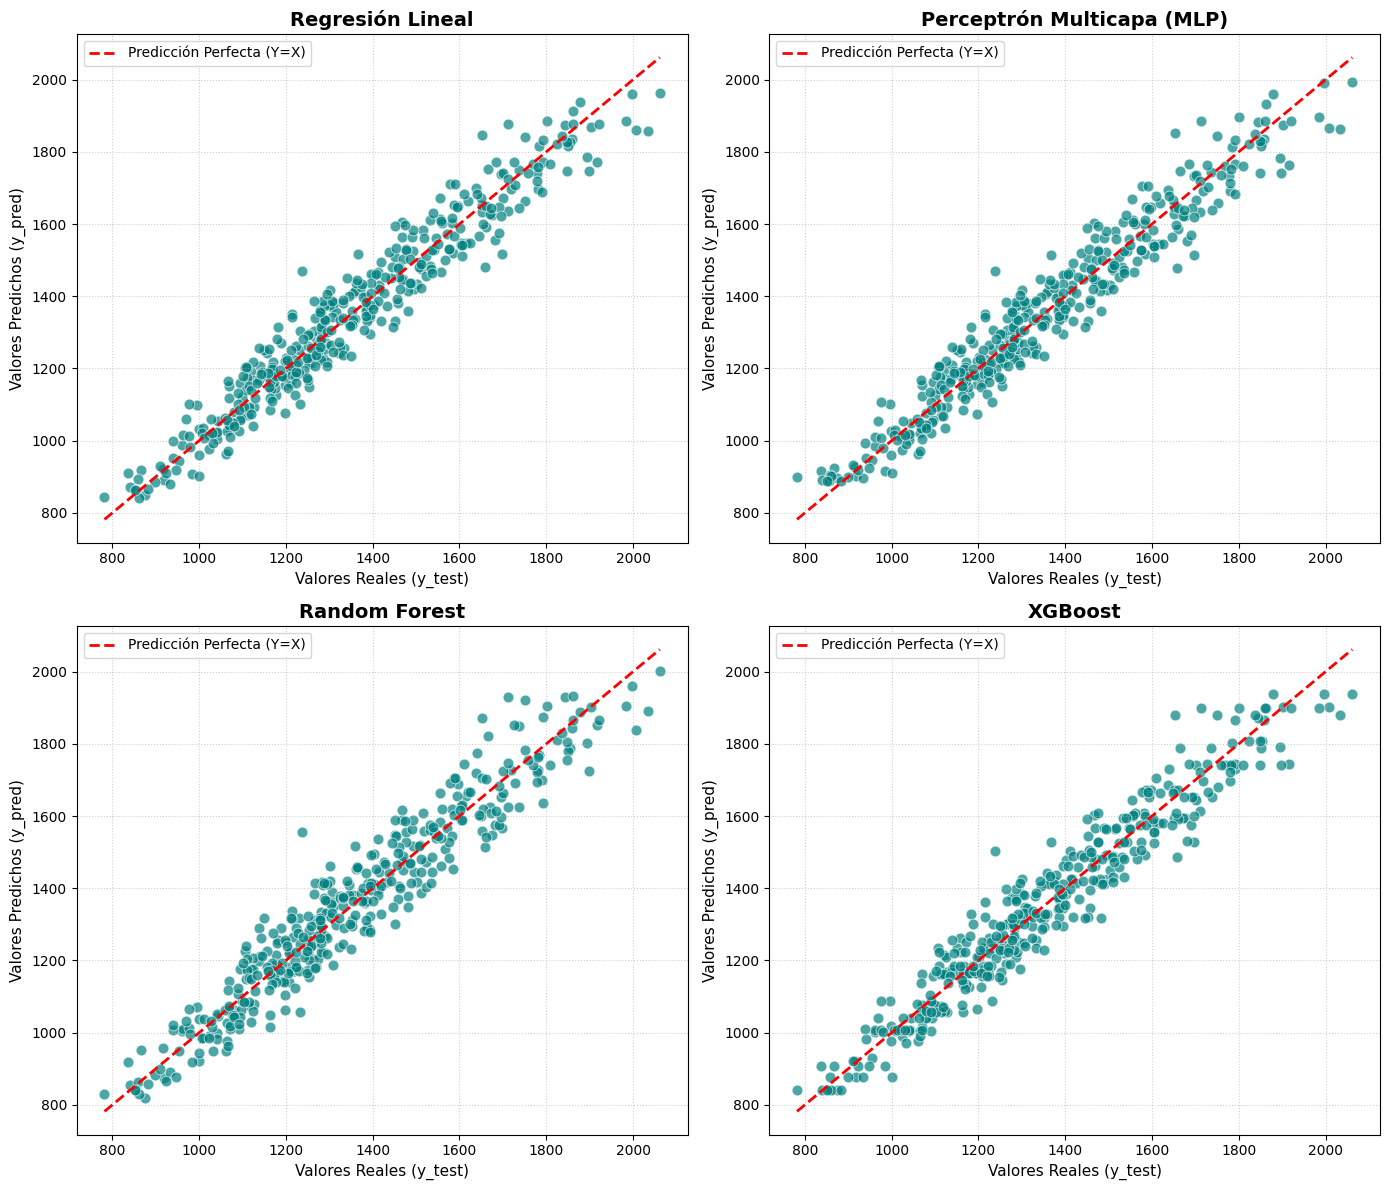

In [ ]:
# ==========================================
# 4. GRÁFICO DE DISPERSIÓN (REAL VS PREDICHO)
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

# Definir los límites para la línea perfecta (y = x)
min_val = min(y_test.min(), min([p.min() for p in predicciones_modelos.values()]))
max_val = max(y_test.max(), max([p.max() for p in predicciones_modelos.values()]))

for idx, (nombre, y_pred) in enumerate(predicciones_modelos.items()):
    ax = axes[idx]

    # Scatter plot de los valores reales vs predichos
    sns.scatterplot(x=y_test, y=y_pred, ax=ax, alpha=0.7, color='teal', edgecolor='w', s=60)

    # Línea de predicción perfecta (y = x)
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Predicción Perfecta (Y=X)')

    # Configuración de cada subgráfico
    ax.set_title(f'{nombre}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Valores Reales (y_test)', fontsize=11)
    ax.set_ylabel('Valores Predichos (y_pred)', fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left')

plt.tight_layout()
#plt.suptitle('Comparación de Valores Reales vs. Predicciones por Modelo', y=1.02, fontsize=16, fontweight='bold')
plt.savefig('comparacion_modelos.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
lin_reg = modelos["Regresión Lineal"]
print(f"Ecuación: Y = {lin_reg.coef_[0]:.2f} * X + {lin_reg.intercept_:.2f}")

Ecuación: Y = 16.51 * X + -1.23


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


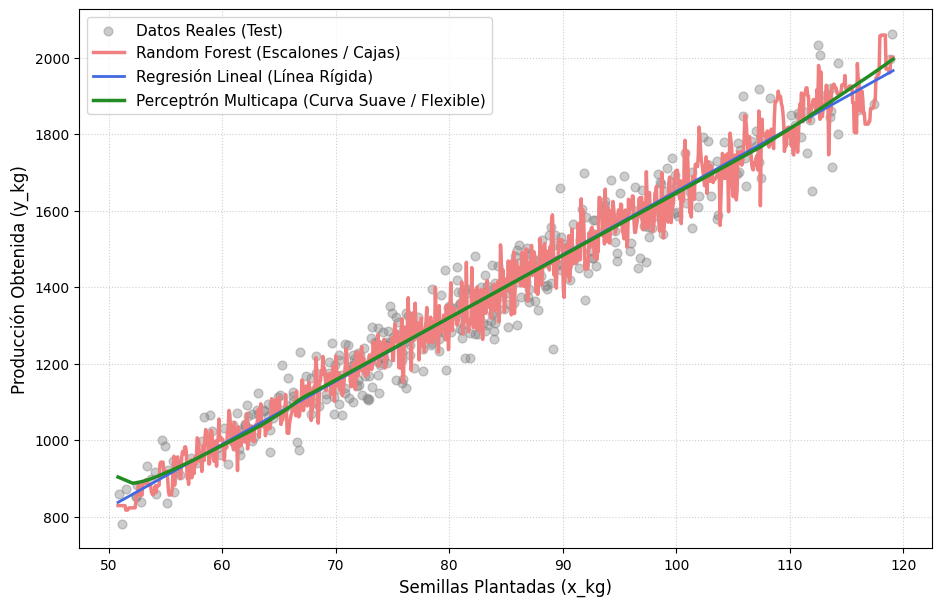

In [ ]:
# ==========================================
# VISUALIZACIÓN COMPARATIVA DE LOS TRES ENFOQUES
# ==========================================

# 1. Creamos la línea continua de valores de semillas para trazar las predicciones
x_linea = np.linspace(X.min(), X.max(), 1000).reshape(-1, 1)

# 2. Calculamos las predicciones para toda la línea en cada modelo
y_pred_lineal = modelos["Regresión Lineal"].predict(x_linea)
y_pred_rf = modelos["Random Forest"].predict(x_linea)
y_pred_mlp = modelos["Perceptrón Multicapa (MLP)"].predict(x_linea)

# 3. Graficamos la comparación
plt.figure(figsize=(11, 7))

# Puntos grises de fondo (los datos reales de prueba)
plt.scatter(X_test, y_test, color='gray', alpha=0.4, label='Datos Reales (Test)', s=40)

# Línea Roja: Random Forest
plt.plot(x_linea, y_pred_rf, color='lightcoral', linewidth=2.5,
         label='Random Forest (Escalones / Cajas)')

# Línea Azul: Regresión Lineal
plt.plot(x_linea, y_pred_lineal, color='royalblue', linewidth=2,
         label='Regresión Lineal (Línea Rígida)')

# Línea Verde: Perceptrón Multicapa (Red Neuronal)
plt.plot(x_linea, y_pred_mlp, color='forestgreen', linewidth=2.5,
         label='Perceptrón Multicapa (Curva Suave / Flexible)')

# Configuración estética del gráfico
#plt.title('Diferencia Visual entre Modelos: Línea vs. Escalera vs. Curva', fontsize=14, fontweight='bold')
plt.xlabel('Semillas Plantadas (x_kg)', fontsize=12)
plt.ylabel('Producción Obtenida (y_kg)', fontsize=12)
plt.legend(fontsize=11, loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)
plt.savefig('c3_comparacion_modelos_linea.png', dpi=300, bbox_inches='tight')

plt.show()

## Crisis

In [ ]:
import numpy as np
import pandas as pd

# ==========================================
# CONFIGURACIÓN DE LA SIMULACIÓN
# ==========================================
n_hectareas = 15
anos = 10
ciclos_por_ano = 2
total_ciclos = anos * ciclos_por_ano

np.random.seed(42)

# Generar la cantidad de semillas ideal para cada terreno
cantidad_x_hectarea = np.random.uniform(100, 150, size=n_hectareas)

registros = []

# ==========================================
# EJECUCIÓN DE LA SIMULACIÓN CON RIESGO (10%)
# ==========================================
for i in range(n_hectareas):
    x_ideal = cantidad_x_hectarea[i]

    for ciclo in range(total_ciclos):
        # Calcular el año y el semestre actual
        ano_actual = 1 + (ciclo // 2)
        semestre_actual = 1 + (ciclo % 2)

        # Variación del cultivo (50% al 80% del ideal)
        factor_variacion = np.random.uniform(0.5, 0.8)
        x_s = x_ideal * factor_variacion

        # Fórmula base de producción con ruido en porcentaje: y = 15x + normal(10%, 5%)
        ruido = np.random.normal(loc=10, scale=5)
        y_s = 15 * x_s
        y_s = (1 + ruido / 100) * y_s

        # MODIFICACIÓN: Probabilidad del 10% de crisis (plaga, sequía, etc.)
        crisis_ocurrida = False
        if np.random.random() < 0.10:
            crisis_ocurrida = True
            # La producción se reduce a un valor entre 0% y 50% de lo esperado
            # Si da 0, la producción final es 0 (pérdida total)
            factor_supervivencia = np.random.uniform(0.0, 0.5)
            y_s = y_s * factor_supervivencia

        # Guardar la información del ciclo actual (incluyendo la columna del ideal)
        registros.append({
            "Hectarea_ID": f"Hectarea_{i+1}",
            "Ideal_Hectarea_kg": x_ideal,
            "Ano": ano_actual,
            "Semestre": semestre_actual,
            "Semillas_Plantadas_x_kg": x_s,
            "Produccion_Obtenida_y_kg": y_s,
            "Crisis_Plaga": 1 if crisis_ocurrida else 0  # 1 si hubo crisis, 0 si fue normal
        })

# Crear el DataFrame final
df_simulacion = pd.DataFrame(registros)

# ==========================================
# VISUALIZACIÓN DE CONTROL
# ==========================================
print(f"¡Simulación con eventos catastróficos completada!")
print(f"Total de registros: {len(df_simulacion)}")
print(f"Total de cosechas afectadas por crisis: {df_simulacion['Crisis_Plaga'].sum()}\n")

# Mostrar una muestra de los datos donde ocurrió una crisis
print("Muestra de ciclos donde ocurrió una pérdida de producción:")
df_con_crisis = df_simulacion[df_simulacion['Crisis_Plaga'] == 1]
print(df_con_crisis.head().to_markdown(index=False))

¡Simulación con eventos catastróficos completada!
Total de registros: 300
Total de cosechas afectadas por crisis: 31

Muestra de ciclos donde ocurrió una pérdida de producción:
| Hectarea_ID   |   Ideal_Hectarea_kg |   Ano |   Semestre |   Semillas_Plantadas_x_kg |   Produccion_Obtenida_y_kg |   Crisis_Plaga |
|:--------------|--------------------:|------:|-----------:|--------------------------:|---------------------------:|---------------:|
| Hectarea_1    |             118.727 |     3 |          2 |                   65.4372 |                    514.846 |              1 |
| Hectarea_1    |             118.727 |     4 |          1 |                   93.7575 |                    514.813 |              1 |
| Hectarea_1    |             118.727 |     6 |          1 |                   65.9477 |                    110.207 |              1 |
| Hectarea_1    |             118.727 |     8 |          2 |                   86.8347 |                    267.162 |              1 |
| Hectarea_3 

### RESULTADOS DE LA DETECCIÓN A CIEGAS ###
Límite estadístico de rendimiento normal: 13.77 kg obtenidos por kilo sembrado.
Total de anomalías detectadas en el histórico: 31

Matriz de Confusión (Validación Cruzada):
|                 |   Predicho Normal |   Predicho Crisis |
|:----------------|------------------:|------------------:|
| Era Normal      |               269 |                 0 |
| Era Crisis Real |                 0 |                31 |




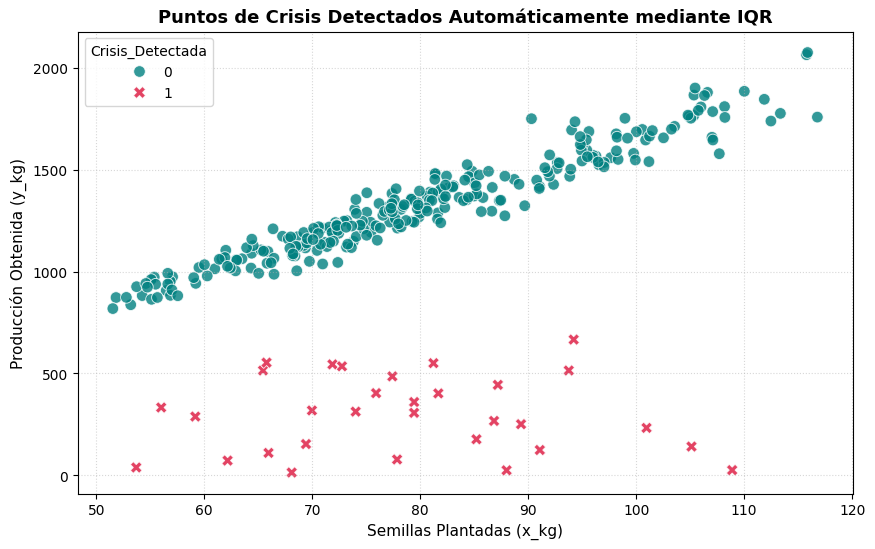

In [ ]:


# ==========================================
# 1. PREPARACIÓN DEL DATASET "A CIEGAS"
# ==========================================
# (Asumimos que df_simulacion ya existe con las crisis del paso anterior)
# Creamos una copia y eliminamos la columna real para simular la vida real

df_historico = df_simulacion.copy()
crisis_reales = df_historico.pop('Crisis_Plaga') # Guardada solo para validar al final

# ==========================================
# 2. DETECCIÓN ANÓMALA (MÉTODO DEL RENDIMIENTO)
# ==========================================

# Paso A: Calcular el rendimiento neto por kilo
df_historico['Rendimiento'] = df_historico['Produccion_Obtenida_y_kg'] / df_historico['Semillas_Plantadas_x_kg']

# Paso B: Calcular los cuartiles del rendimiento
Q1 = df_historico['Rendimiento'].quantile(0.25)
Q3 = df_historico['Rendimiento'].quantile(0.75)
IQR = Q3 - Q1

# Paso C: Definir el límite inferior para detectar anomalías
# Cualquier rendimiento que esté muy por debajo del comportamiento normal se bandera como crisis
limite_inferior = Q1 - 1.5 * IQR

# Paso D: Marcar las crisis detectadas a ciegas
df_historico['Crisis_Detectada'] = np.where(df_historico['Rendimiento'] < limite_inferior, 1, 0)

# ==========================================
# 3. EVALUACIÓN DE LA DETECCIÓN
# ==========================================
print(f"### RESULTADOS DE LA DETECCIÓN A CIEGAS ###")
print(f"Límite estadístico de rendimiento normal: {limite_inferior:.2f} kg obtenidos por kilo sembrado.")
print(f"Total de anomalías detectadas en el histórico: {df_historico['Crisis_Detectada'].sum()}\n")

# Matriz de Confusión para ver si le atinamos a la realidad oculta
cm = confusion_matrix(crisis_reales, df_historico['Crisis_Detectada'])
df_cm = pd.DataFrame(cm, index=['Era Normal', 'Era Crisis Real'], columns=['Predicho Normal', 'Predicho Crisis'])

print("Matriz de Confusión (Validación Cruzada):")
print(df_cm.to_markdown())
print("\n" + "="*50 + "\n")

# ==========================================
# 4. GRÁFICO DE ANOMALÍAS DETECTADAS
# ==========================================
plt.figure(figsize=(10, 6))

# Pintamos los puntos usando la etiqueta que nuestro algoritmo DESCUBRIÓ solo
sns.scatterplot(
    data=df_historico,
    x='Semillas_Plantadas_x_kg',
    y='Produccion_Obtenida_y_kg',
    hue='Crisis_Detectada',
    palette={0: 'teal', 1: 'crimson'},
    alpha=0.8,
    s=70,
    style='Crisis_Detectada',
    markers={0: 'o', 1: 'X'}
)

plt.title('Puntos de Crisis Detectados Automáticamente mediante IQR', fontsize=13, fontweight='bold')
plt.xlabel('Semillas Plantadas (x_kg)', fontsize=11)
plt.ylabel('Producción Obtenida (y_kg)', fontsize=11)
#plt.legend(title='Algoritmo IQR', labels=['Funcionamiento Normal', 'Anomalía / Crisis Detectada'])
plt.grid(True, linestyle=':', alpha=0.5)
plt.savefig('c3_analisis_crisis.png', dpi=300, bbox_inches='tight')
plt.show()

### Entrenar modelos con crisis

In [ ]:
# ==========================================
# 1. GENERACIÓN DEL DATASET HISTÓRICO (CON 10% CRISIS)
# ==========================================
n_hectareas = 15
anos = 10
ciclos_por_ano = 2
total_ciclos = anos * ciclos_por_ano

np.random.seed(42)
cantidad_x_hectarea = np.random.uniform(100, 150, size=n_hectareas)

registros = []
for i in range(n_hectareas):
    x_ideal = cantidad_x_hectarea[i]
    for ciclo in range(total_ciclos):
        ano_actual = 1 + (ciclo // 2)
        semestre_actual = 1 + (ciclo % 2)

        factor_variacion = np.random.uniform(0.5, 0.8)
        x_s = x_ideal * factor_variacion

        ruido = np.random.normal(loc=10, scale=5)
        y_s = 15 * x_s
        y_s = (1 + ruido / 100) * y_s

        # 10% de probabilidad de crisis
        if np.random.random() < 0.10:
            y_s = y_s * np.random.uniform(0.0, 0.5)

        registros.append({
            "Semillas_Plantadas_x_kg": x_s,
            "Produccion_Obtenida_y_kg": y_s
        })

df_completo = pd.DataFrame(registros)

# Split original (Posición ingenua)
X = df_completo[['Semillas_Plantadas_x_kg']]
y = df_completo['Produccion_Obtenida_y_kg']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==========================================
# 2. LIMPIEZA DE OUTLIERS MEDIANTE IQR (TRAIN Y TEST)
# ==========================================
# Calculamos el umbral basado en el rendimiento del set de entrenamiento
rendimiento_train = y_train / X_train['Semillas_Plantadas_x_kg']
Q1 = rendimiento_train.quantile(0.25)
Q3 = rendimiento_train.quantile(0.75)
IQR = Q3 - Q1
limite_inferior = Q1 - 1.5 * IQR

# Set de Entrenamiento Limpio
mascara_train_limpios = rendimiento_train >= limite_inferior
X_train_clean = X_train[mascara_train_limpios]
y_train_clean = y_train[mascara_train_limpios]

# Set de Testeo Limpio (Condiciones ideales para evaluar)
rendimiento_test = y_test / X_test['Semillas_Plantadas_x_kg']
mascara_test_limpios = rendimiento_test >= limite_inferior
X_test_clean = X_test[mascara_test_limpios]
y_test_clean = y_test[mascara_test_limpios]

# ==========================================
# 3. ENTRENAMIENTO DE LOS MODELOS
# ==========================================
def obtener_modelos():
    return {
        "Regresión Lineal": LinearRegression(),
        "MLP (Red Neuronal)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=3000, random_state=42)),
        "Random Forest": RandomForestRegressor(random_state=42),
        "XGBoost": XGBRegressor(random_state=42)
    }

modelos_con_outliers = obtener_modelos()
modelos_sin_outliers = obtener_modelos()

for name, model in modelos_con_outliers.items():
    model.fit(X_train, y_train)

for name, model in modelos_sin_outliers.items():
    model.fit(X_train_clean, y_train_clean)

# ==========================================
# 4. EVALUACIÓN EN EL CONJUNTO DE TEST LIMPIO (CONDICIONES IDEALES)
# ==========================================
resultados_ideales = []
for name in modelos_con_outliers.keys():
    pred_con = modelos_con_outliers[name].predict(X_test_clean)
    pred_sin = modelos_sin_outliers[name].predict(X_test_clean)

    resultados_ideales.append({
        "Modelo": name,
        "RMSE (Entrenado Con)": round(np.sqrt(mean_squared_error(y_test_clean, pred_con)), 2),
        "RMSE (Entrenado Sin)": round(np.sqrt(mean_squared_error(y_test_clean, pred_sin)), 2),
        "R2 (Entrenado Con)": round(r2_score(y_test_clean, pred_con), 3),
        "R2 (Entrenado Sin)": round(r2_score(y_test_clean, pred_sin), 3)
    })

print("### EVALUACIÓN EN CONDICIONES IDEALES (TEST SET SIN OUTLIERS) ###")
print(pd.DataFrame(resultados_ideales).to_markdown(index=False))
print("\n" + "="*80 + "\n")


### EVALUACIÓN EN CONDICIONES IDEALES (TEST SET SIN OUTLIERS) ###
| Modelo             |   RMSE (Entrenado Con) |   RMSE (Entrenado Sin) |   R2 (Entrenado Con) |   R2 (Entrenado Sin) |
|:-------------------|-----------------------:|-----------------------:|---------------------:|---------------------:|
| Regresión Lineal   |                 147.85 |                  85.98 |                0.633 |                0.876 |
| MLP (Red Neuronal) |                 144    |                  87.47 |                0.652 |                0.872 |
| Random Forest      |                 244.68 |                  89.86 |               -0.005 |                0.864 |
| XGBoost            |                 339.7  |                  97.9  |               -0.937 |                0.839 |




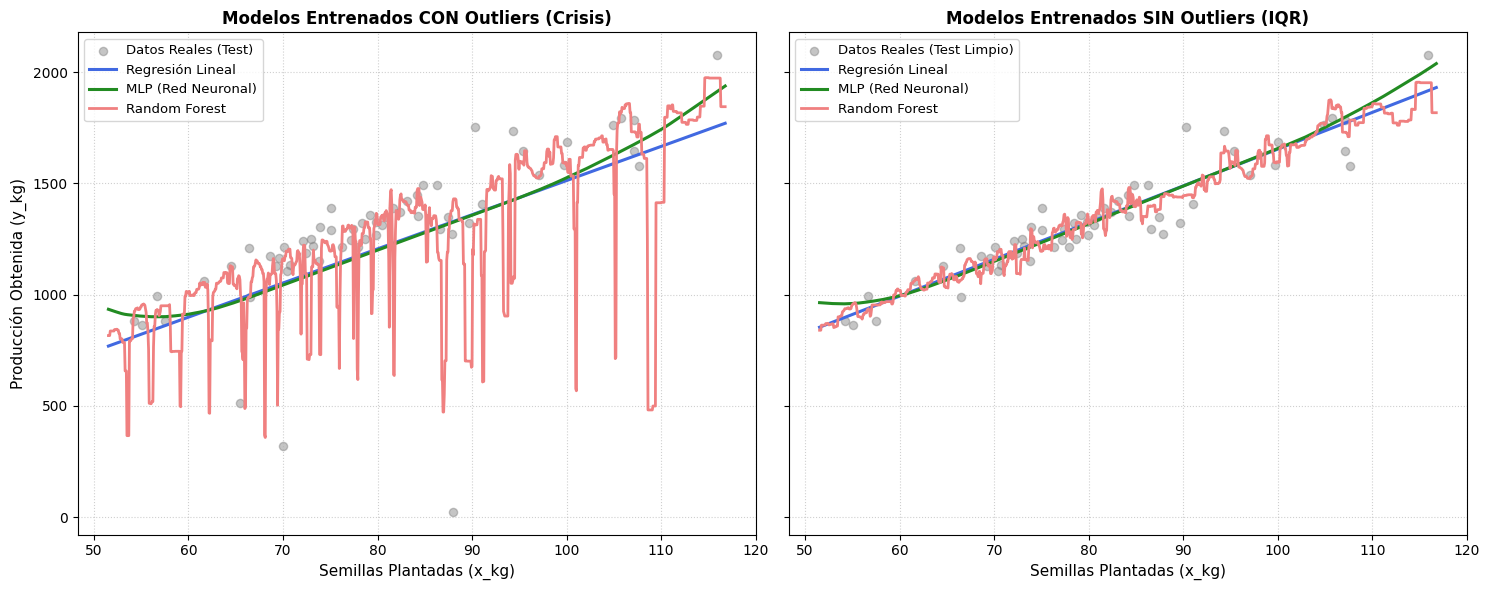

In [ ]:
# ==========================================
# 2. VISUALIZACIÓN COMPARATIVA DOBLE
# ==========================================
# Grid continuo para trazar las curvas de predicción
x_linea = pd.DataFrame(
    np.linspace(X.min().values[0], X.max().values[0], 1000),
    columns=['Semillas_Plantadas_x_kg']
)

# Estilos visuales consistentes con tu gráfico original
estilos = {
    "Regresión Lineal": {"color": "royalblue", "linestyle": "-", "linewidth": 2.2},
    "MLP (Red Neuronal)": {"color": "forestgreen", "linestyle": "-", "linewidth": 2.2},
    "Random Forest": {"color": "lightcoral", "linestyle": "-", "linewidth": 2}
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# ------------------------------------------
# PANEL IZQUIERDO: MODELOS CON OUTLIERS
# ------------------------------------------
axes[0].scatter(X_test, y_test, color='gray', alpha=0.45, s=35, label='Datos Reales (Test)')

for name, model in modelos_con_outliers.items():
  if name == "XGBoost":
    continue
  y_pred = model.predict(x_linea)
  axes[0].plot(x_linea, y_pred, label=name, **estilos[name])

axes[0].set_title('Modelos Entrenados CON Outliers (Crisis)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Semillas Plantadas (x_kg)', fontsize=11)
axes[0].set_ylabel('Producción Obtenida (y_kg)', fontsize=11)
axes[0].legend(fontsize=9.5, loc='upper left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# ------------------------------------------
# PANEL DERECHO: MODELOS SIN OUTLIERS (LIMPIOS)
# ------------------------------------------
axes[1].scatter(X_test_clean, y_test_clean, color='gray', alpha=0.45, s=35, label='Datos Reales (Test Limpio)')

for name, model in modelos_sin_outliers.items():
  if name == "XGBoost":
    continue
  y_pred = model.predict(x_linea)
  axes[1].plot(x_linea, y_pred, label=name, **estilos[name])

axes[1].set_title('Modelos Entrenados SIN Outliers (IQR)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Semillas Plantadas (x_kg)', fontsize=11)
axes[1].legend(fontsize=9.5, loc='upper left')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('c3_comparacion_modelos_doble.png', dpi=300, bbox_inches='tight')
plt.show()

## Juego económico

In [ ]:

# ==========================================
# 1. SIMULACIÓN DE 1 AÑO NUEVO EN EL MUNDO REAL (CON 10% CRISIS)
# ==========================================
nuevos_semestres = 2
registros_negocio = []

# Semilla fija para que la realidad sea idéntica en todas las evaluaciones
np.random.seed(2026)

for i in range(n_hectareas):
    x_ideal = cantidad_x_hectarea[i]

    for semestre in range(nuevos_semestres):
        factor_variacion = np.random.uniform(0.5, 0.8)
        x_s = x_ideal * factor_variacion

        # Producción Base con ruido en porcentaje
        ruido = np.random.normal(loc=10, scale=5)
        y_real = 15 * x_s
        y_real = (1 + ruido / 100) * y_real

        # El mundo real tiene imprevistos: 10% de probabilidad de crisis extrema
        if np.random.random() < 0.10:
            y_real = y_real * np.random.uniform(0.0, 0.5)

        registros_negocio.append({
            "Hectarea_ID": f"Hectarea_{i+1}",
            "Semestre": semestre + 1,
            "Semillas_Plantadas_x_kg": x_s,
            "Produccion_Real_y_kg": y_real
        })

df_negocio_real = pd.DataFrame(registros_negocio)

# ==========================================
# 2. EVALUACIÓN DE ESTRATEGIAS (RECOLECCIÓN LIMPIA)
# ==========================================
X_negocio = df_negocio_real[['Semillas_Plantadas_x_kg']]
resumen_impacto = []

enfoques = [
    ("Con Outliers", modelos_con_outliers),
    ("Sin Outliers", modelos_sin_outliers)
]

for sufijo, dict_modelos in enfoques:
    for nombre, modelo in dict_modelos.items():
        y_pred = modelo.predict(X_negocio)
        Z_comprometido = (y_pred // 100) * 100

        df_eval = df_negocio_real.copy()
        df_eval['Contrato_Z_kg'] = Z_comprometido

        df_eval

In [ ]:
# ==============================================================================
# 2. EVALUACIÓN ECONÓMICA Y FINANCIERA (CON VS SIN OUTLIERS)
# ==============================================================================

# --- PARÁMETROS ECONÓMICOS ---
PRECIO_CONTRATO_BASE = 10.0  # $ por kg acordado en contrato

X_negocio = df_negocio_real[['Semillas_Plantadas_x_kg']]

enfoques = [
    ("Con Outliers", modelos_con_outliers),
    ("Sin Outliers", modelos_sin_outliers)
]

# Función para evaluar el negocio bajo cualquier combinación de multa y remate spot
def evaluar_balance_economico(tasa_multa=1.0, factor_spot=0.65):
    resultados = []

    for sufijo, dict_modelos in enfoques:
        for nombre, modelo in dict_modelos.items():
            y_pred = modelo.predict(X_negocio)
            Z_comprometido = (y_pred // 100) * 100

            df_eval = df_negocio_real.copy()
            df_eval['Contrato_Z_kg'] = Z_comprometido

            # Balances físicos (kg)
            df_eval['Entregado_Contrato_kg'] = np.minimum(df_eval['Produccion_Real_y_kg'], df_eval['Contrato_Z_kg'])
            df_eval['Sobrante_kg'] = np.maximum(0, df_eval['Produccion_Real_y_kg'] - df_eval['Contrato_Z_kg'])
            df_eval['Faltante_kg'] = np.maximum(0, df_eval['Contrato_Z_kg'] - df_eval['Produccion_Real_y_kg'])

            # Balances económicos ($)
            df_eval['Ingreso_Contratos'] = df_eval['Entregado_Contrato_kg'] * PRECIO_CONTRATO_BASE
            df_eval['Ingreso_Spot'] = df_eval['Sobrante_kg'] * (PRECIO_CONTRATO_BASE * factor_spot)
            df_eval['Pago_Multas'] = df_eval['Faltante_kg'] * (PRECIO_CONTRATO_BASE * tasa_multa)
            df_eval['Ganancia_Neta'] = df_eval['Ingreso_Contratos'] + df_eval['Ingreso_Spot'] - df_eval['Pago_Multas']

            resultados.append({
                "Enfoque": sufijo,
                "Modelo": nombre,
                "Tasa_Multa": tasa_multa,
                "Factor_Spot": factor_spot,
                "Contrato_Total_kg": df_eval['Contrato_Z_kg'].sum(),
                "Faltante_Total_kg": df_eval['Faltante_kg'].sum(),
                "Sobrante_Total_kg": df_eval['Sobrante_kg'].sum(),
                "Ingreso_Contratos_$": df_eval['Ingreso_Contratos'].sum(),
                "Ingreso_Spot_$": df_eval['Ingreso_Spot'].sum(),
                "Pago_Multas_$": df_eval['Pago_Multas'].sum(),
                "Ganancia_Neta_$": df_eval['Ganancia_Neta'].sum()
            })

    return pd.DataFrame(resultados)


# ==============================================================================
# 3. REPORTE TIPO INFORME FINANCIERO
# ==============================================================================
# Escenario Base (Multa estándar 1.0x, Venta Spot a 0.65x)
df_base = evaluar_balance_economico(tasa_multa=1.0, factor_spot=0.65)

print("=" * 80)
print("                   INFORME DE EVALUACIÓN FINANCIERA")
print("=" * 80)
print(f"Parámetros Base:")
print(f" - Precio Contrato:         ${PRECIO_CONTRATO_BASE:.2f} / kg")
print(f" - Multa por Incumplimiento: 1.00x del valor faltante")
print(f" - Venta Spot / Remate:      0.65x (${PRECIO_CONTRATO_BASE * 0.65:.2f} / kg)")
print("-" * 80)

for _, row in df_base.iterrows():
    print(f"ESTRATEGIA: {row['Enfoque'].upper()} ({row['Modelo']})")
    print(f"  * Volumen Contratado:       {row['Contrato_Total_kg']:>10,.1f} kg")
    print(f"  * Déficit Total (Faltante): {row['Faltante_Total_kg']:>10,.1f} kg")
    print(f"  * Excedente Total (Sobrante):{row['Sobrante_Total_kg']:>9,.1f} kg")
    print(f"  * (+) Ingreso por Contratos:  ${row['Ingreso_Contratos_$']:>12,.2f}")
    print(f"  * (+) Ingreso Venta Spot:     ${row['Ingreso_Spot_$']:>12,.2f}")
    print(f"  * (-) Pago Total en Multas:   ${row['Pago_Multas_$']:>12,.2f}")
    print(f"  --------------------------------------------------")
    print(f"  * (=) GANANCIA NETA:          ${row['Ganancia_Neta_$']:>12,.2f}\n")

# Matriz de Sensibilidad (Evolución de Multas: 0.5 a 1.5 | Spot: 0.5 a 0.8)
matriz_escenarios = []
for tm in [0.5, 1.0, 1.5]:
    for fs in [0.50, 0.65, 0.80]:
        matriz_escenarios.append(evaluar_balance_economico(tasa_multa=tm, factor_spot=fs))

df_informe_matriz = pd.concat(matriz_escenarios, ignore_index=True)

print("=" * 80)
print("TABLA COMPARATIVA DE ESCENARIOS (SENSIBILIDAD MULTAS Y SPOT)")
print("=" * 80)
tabla_print = df_informe_matriz[[
    'Enfoque', 'Tasa_Multa', 'Factor_Spot',
    'Ingreso_Contratos_$', 'Ingreso_Spot_$', 'Pago_Multas_$', 'Ganancia_Neta_$'
]].copy()
tabla_print.columns = ['Enfoque', 'Multa (x)', 'Spot (x)', 'Contratos ($)', 'Spot ($)', 'Multas ($)', 'Ganancia Neta ($)']
print(tabla_print.to_markdown(index=False, floatfmt=",.2f"))
print("\n" + "=" * 80 + "\n")


                   INFORME DE EVALUACIÓN FINANCIERA
Parámetros Base:
 - Precio Contrato:         $10.00 / kg
 - Multa por Incumplimiento: 1.00x del valor faltante
 - Venta Spot / Remate:      0.65x ($6.50 / kg)
--------------------------------------------------------------------------------
ESTRATEGIA: CON OUTLIERS (Regresión Lineal)
  * Volumen Contratado:         36,000.0 kg
  * Déficit Total (Faltante):    4,842.8 kg
  * Excedente Total (Sobrante):  3,826.6 kg
  * (+) Ingreso por Contratos:  $  311,572.35
  * (+) Ingreso Venta Spot:     $   24,872.88
  * (-) Pago Total en Multas:   $   48,427.65
  --------------------------------------------------
  * (=) GANANCIA NETA:          $  288,017.58

ESTRATEGIA: CON OUTLIERS (MLP (Red Neuronal))
  * Volumen Contratado:         36,300.0 kg
  * Déficit Total (Faltante):    4,871.5 kg
  * Excedente Total (Sobrante):  3,555.3 kg
  * (+) Ingreso por Contratos:  $  314,285.47
  * (+) Ingreso Venta Spot:     $   23,109.35
  * (-) Pago Total en Mu

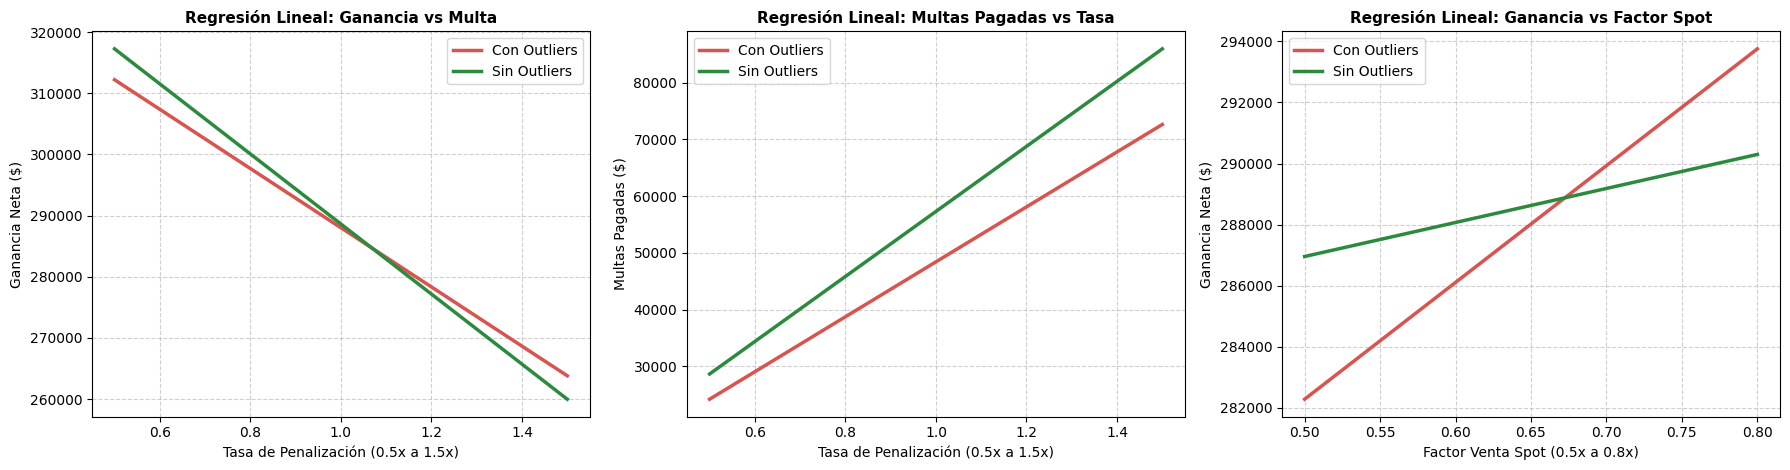

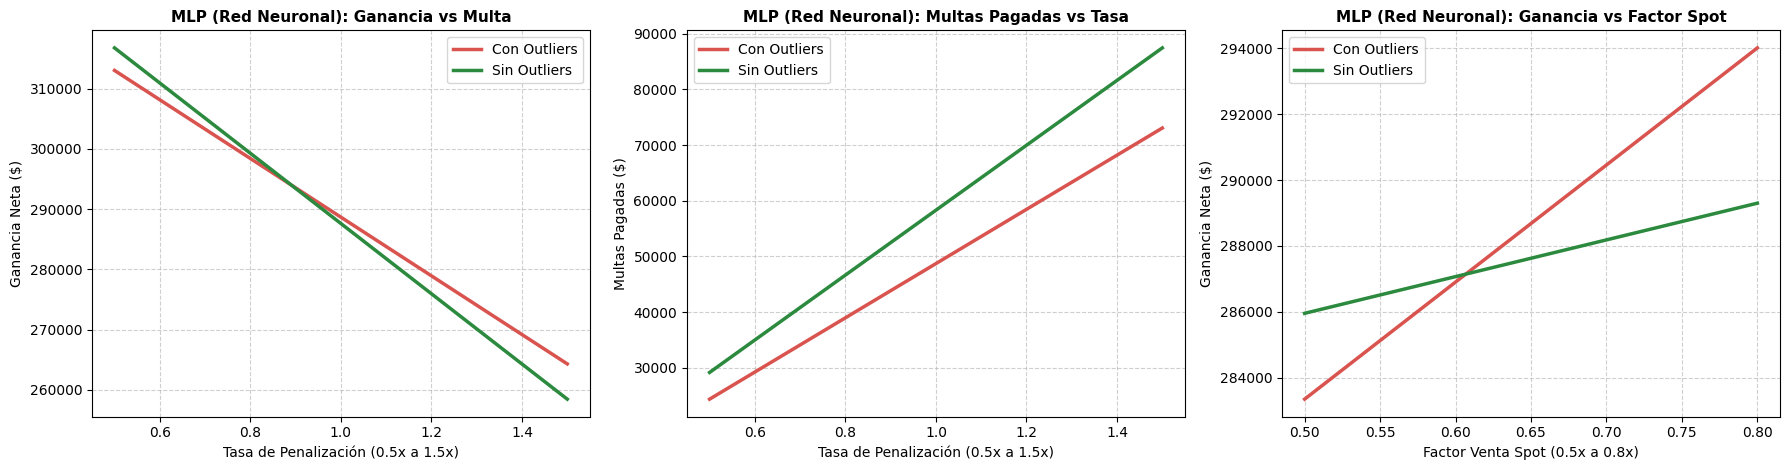

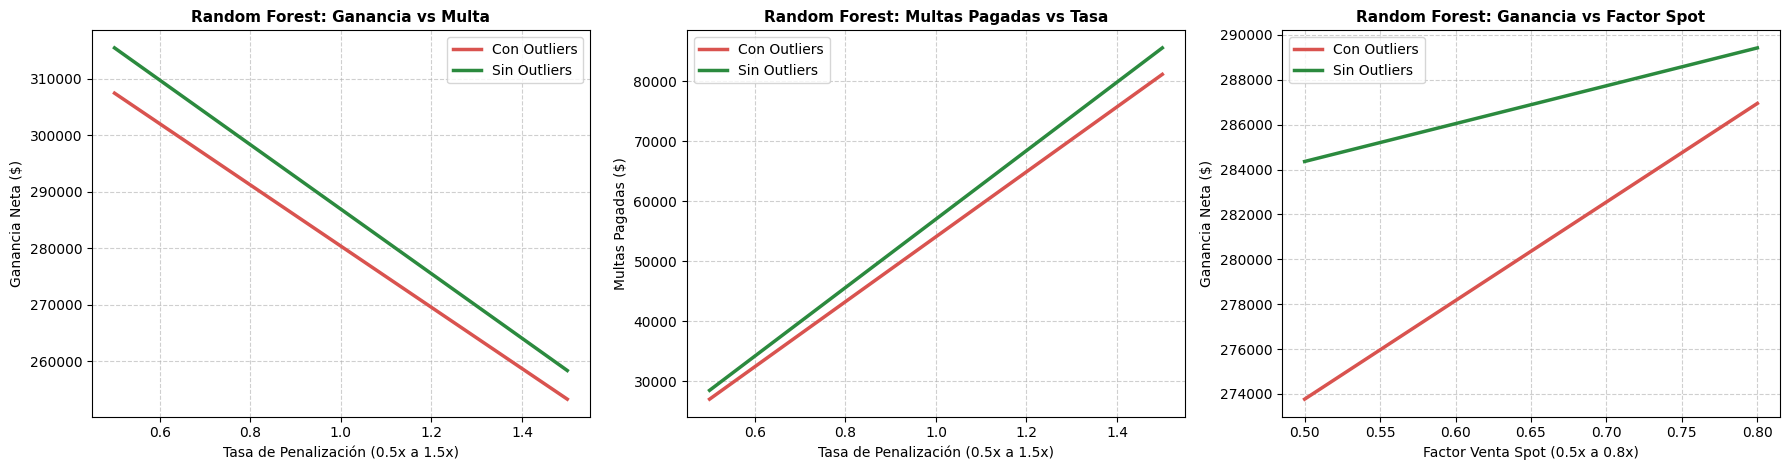

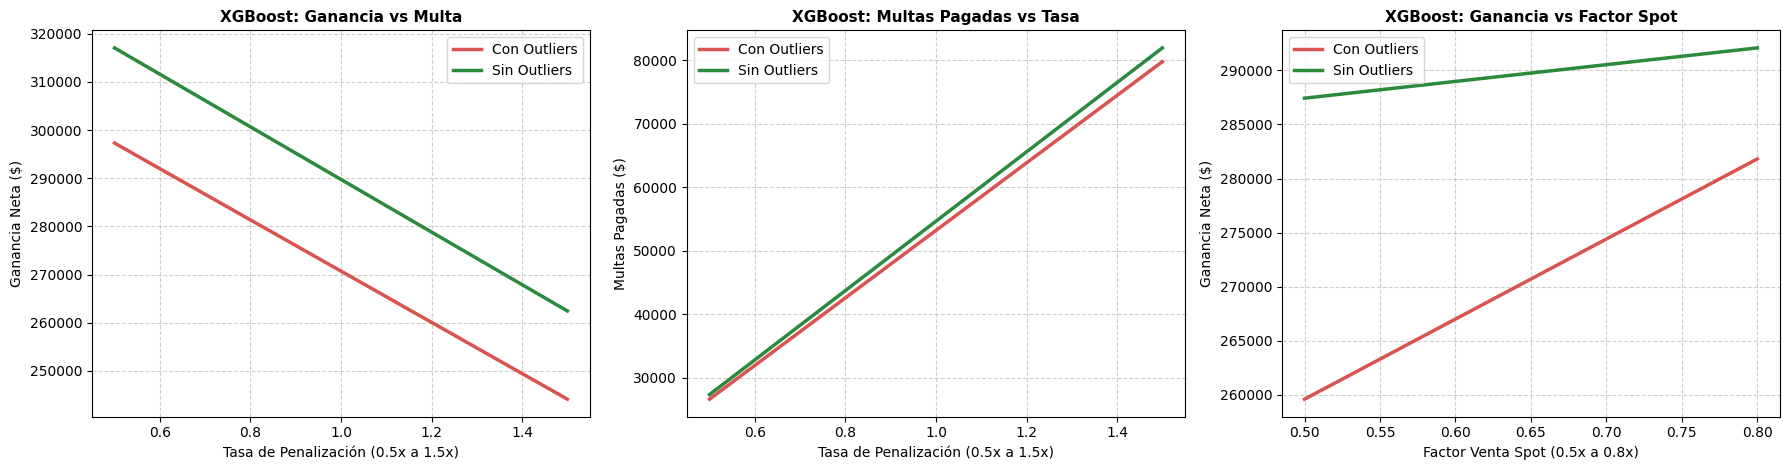

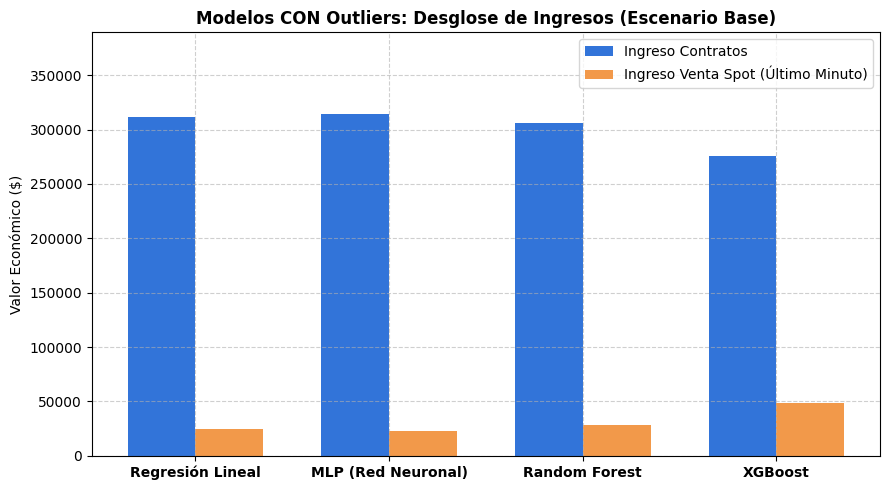

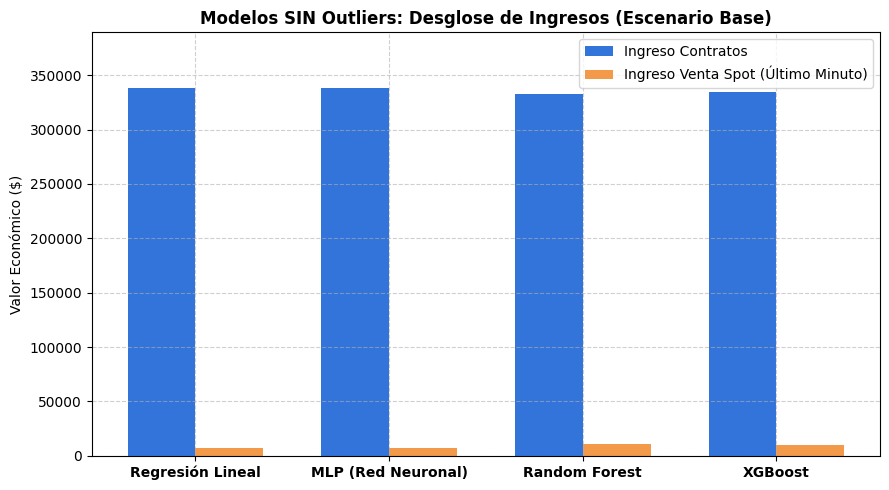

In [ ]:
# ==============================================================================
# 1. GRÁFICAS DE LÍNEAS INDEPENDIENTES (1x3) PARA CADA MODELO
# ==============================================================================
tasas_sweep = np.linspace(0.5, 1.5, 50)
spot_sweep = np.linspace(0.5, 0.8, 50)

# Realizar barridos paramétricos completos
df_sweep_multas_todos = pd.concat([evaluar_balance_economico(tm, 0.65) for tm in tasas_sweep], ignore_index=True)
df_sweep_spot_todos = pd.concat([evaluar_balance_economico(1.0, fs) for fs in spot_sweep], ignore_index=True)

# Obtener todos los nombres de modelos presentes
nombres_modelos = df_base['Modelo'].unique()

# Iterar para generar una figura (1x3) por cada modelo disponible
for modelo_nombre in nombres_modelos:
    df_m_multas = df_sweep_multas_todos[df_sweep_multas_todos['Modelo'] == modelo_nombre]
    df_m_spot = df_sweep_spot_todos[df_sweep_spot_todos['Modelo'] == modelo_nombre]

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

    # Panel 1: Ganancia Neta vs Tasa de Multa
    for enfoque, color in zip(["Con Outliers", "Sin Outliers"], ["#d9534f", "#2b8a3e"]):
        sub = df_m_multas[df_m_multas['Enfoque'] == enfoque]
        axes[0].plot(sub['Tasa_Multa'], sub['Ganancia_Neta_$'], label=enfoque, color=color, linewidth=2.5)
    axes[0].set_title(f"{modelo_nombre}: Ganancia vs Multa", fontweight='bold', fontsize=11)
    axes[0].set_xlabel("Tasa de Penalización (0.5x a 1.5x)")
    axes[0].set_ylabel("Ganancia Neta ($)")
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.6)

    # Panel 2: Pago de Multas vs Tasa de Penalización
    for enfoque, color in zip(["Con Outliers", "Sin Outliers"], ["#d9534f", "#2b8a3e"]):
        sub = df_m_multas[df_m_multas['Enfoque'] == enfoque]
        axes[1].plot(sub['Tasa_Multa'], sub['Pago_Multas_$'], label=enfoque, color=color, linewidth=2.5)
    axes[1].set_title(f"{modelo_nombre}: Multas Pagadas vs Tasa", fontweight='bold', fontsize=11)
    axes[1].set_xlabel("Tasa de Penalización (0.5x a 1.5x)")
    axes[1].set_ylabel("Multas Pagadas ($)")
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    # Panel 3: Ganancia Neta vs Factor Spot
    for enfoque, color in zip(["Con Outliers", "Sin Outliers"], ["#d9534f", "#2b8a3e"]):
        sub = df_m_spot[df_m_spot['Enfoque'] == enfoque]
        axes[2].plot(sub['Factor_Spot'], sub['Ganancia_Neta_$'], label=enfoque, color=color, linewidth=2.5)
    axes[2].set_title(f"{modelo_nombre}: Ganancia vs Factor Spot", fontweight='bold', fontsize=11)
    axes[2].set_xlabel("Factor Venta Spot (0.5x a 0.8x)")
    axes[2].set_ylabel("Ganancia Neta ($)")
    axes[2].legend()
    axes[2].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()


# ==============================================================================
# 2. GRÁFICO DE BARRAS INDEPENDIENTE: MODELOS CON OUTLIERS
# ==============================================================================
df_base_con = df_base[df_base['Enfoque'] == 'Con Outliers'].reset_index(drop=True)
df_base_sin = df_base[df_base['Enfoque'] == 'Sin Outliers'].reset_index(drop=True)

# Escala máxima compartida para comparar visualmente ambos gráficos de barras
max_y_barras = max(
    df_base_con[['Ingreso_Contratos_$', 'Ingreso_Spot_$']].values.max(),
    df_base_sin[['Ingreso_Contratos_$', 'Ingreso_Spot_$']].values.max()
) * 1.15

bar_w = 0.35

plt.figure(figsize=(9, 5))
x_con = np.arange(len(df_base_con))
plt.bar(x_con - bar_w/2, df_base_con['Ingreso_Contratos_$'], width=bar_w, label='Ingreso Contratos', color='#3274d9')
plt.bar(x_con + bar_w/2, df_base_con['Ingreso_Spot_$'], width=bar_w, label='Ingreso Venta Spot (Último Minuto)', color='#f2994a')
plt.xticks(x_con, df_base_con['Modelo'], fontweight='bold')
plt.ylim(0, max_y_barras)
plt.title("Modelos CON Outliers: Desglose de Ingresos (Escenario Base)", fontweight='bold')
plt.ylabel("Valor Económico ($)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


# ==============================================================================
# 3. GRÁFICO DE BARRAS INDEPENDIENTE: MODELOS SIN OUTLIERS
# ==============================================================================
plt.figure(figsize=(9, 5))
x_sin = np.arange(len(df_base_sin))
plt.bar(x_sin - bar_w/2, df_base_sin['Ingreso_Contratos_$'], width=bar_w, label='Ingreso Contratos', color='#3274d9')
plt.bar(x_sin + bar_w/2, df_base_sin['Ingreso_Spot_$'], width=bar_w, label='Ingreso Venta Spot (Último Minuto)', color='#f2994a')
plt.xticks(x_sin, df_base_sin['Modelo'], fontweight='bold')
plt.ylim(0, max_y_barras)
plt.title("Modelos SIN Outliers: Desglose de Ingresos (Escenario Base)", fontweight='bold')
plt.ylabel("Valor Económico ($)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

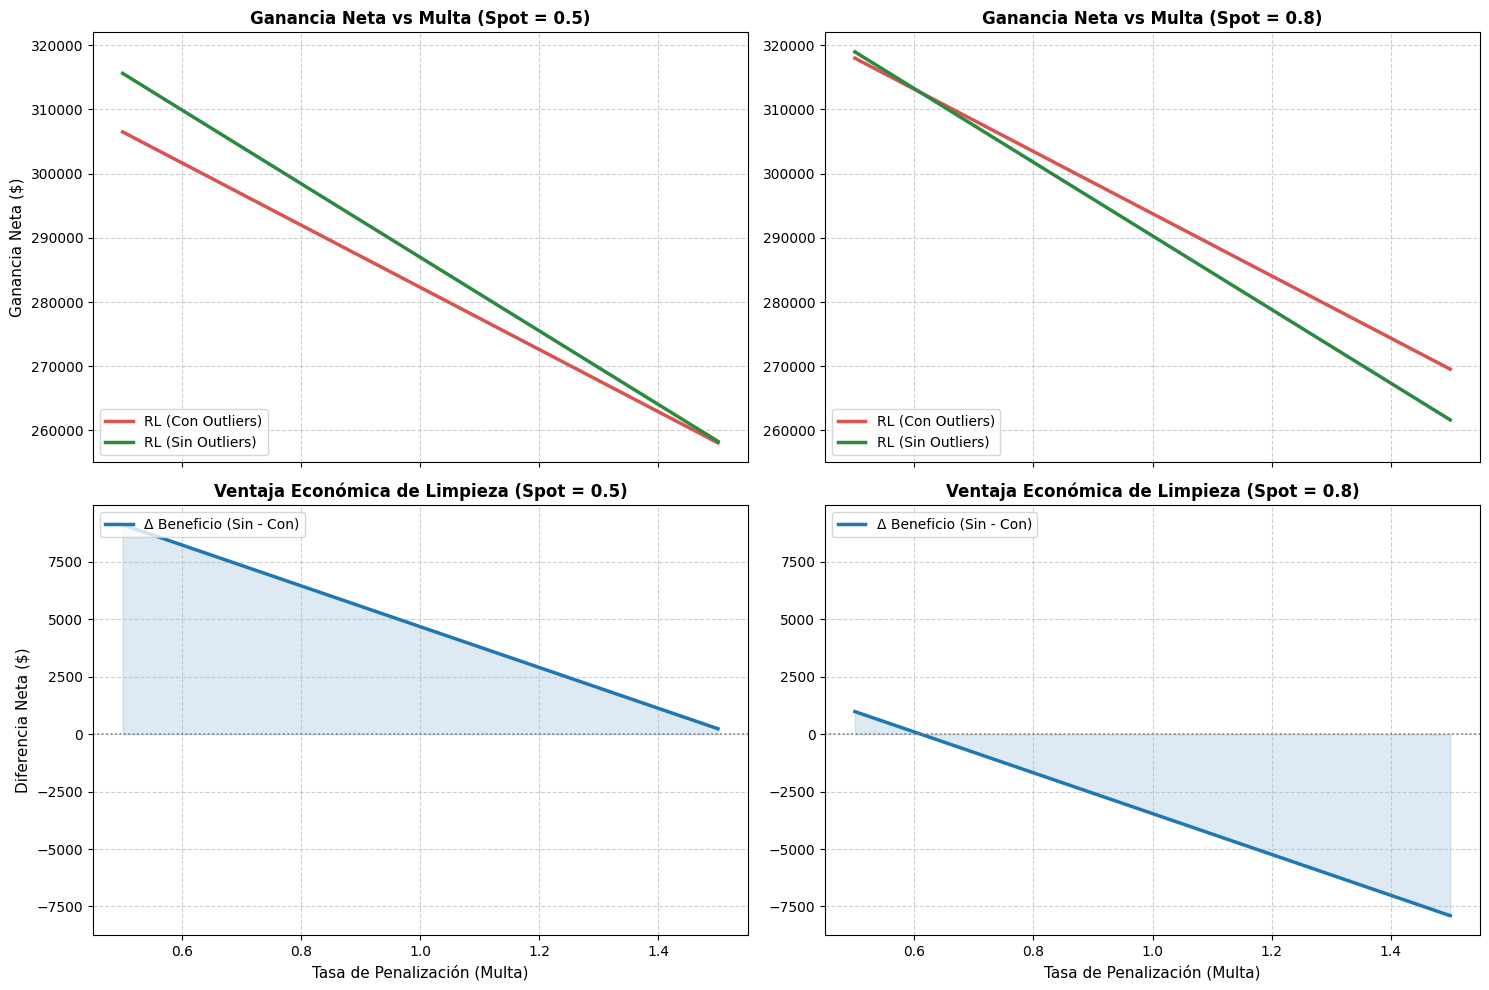

In [ ]:
# ==============================================================================
# BARRIDO DE MULTAS CON SPOT = 0.5 Y SPOT = 0.8 (REGRESIÓN LINEAL)
# ==============================================================================
tasas_sweep = np.linspace(0.5, 1.5, 50)

# 1. Generación de datos para Spot = 0.5
df_sweep_05 = pd.concat(
    [evaluar_balance_economico(tm, 0.5) for tm in tasas_sweep],
    ignore_index=True,
)
df_sweep_05_lr = df_sweep_05[df_sweep_05['Modelo'] == 'Regresión Lineal']

# 2. Generación de datos para Spot = 0.8
df_sweep_08 = pd.concat(
    [evaluar_balance_economico(tm, 0.8) for tm in tasas_sweep],
    ignore_index=True,
)
df_sweep_08_lr = df_sweep_08[df_sweep_08['Modelo'] == 'Regresión Lineal']

# 3. Cálculo de la diferencia neta (Sin Outliers menos Con Outliers)
piv_05 = df_sweep_05_lr.pivot(
    index='Tasa_Multa', columns='Enfoque', values='Ganancia_Neta_$'
)
diff_05 = piv_05['Sin Outliers'] - piv_05['Con Outliers']

piv_08 = df_sweep_08_lr.pivot(
    index='Tasa_Multa', columns='Enfoque', values='Ganancia_Neta_$'
)
diff_08 = piv_08['Sin Outliers'] - piv_08['Con Outliers']

# ==============================================================================
# GRÁFICAS COMPARATIVAS 2x2 (NIVELES ABSOLUTOS Y DIFERENCIAL)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)

# Vinculamos la escala vertical por fila para mantener coherencia métrica
axes[0, 1].sharey(axes[0, 0])
axes[1, 1].sharey(axes[1, 0])

# ------------------------------------------------------------------------------
# FILA 1: GANANCIA NETA ABSOLUTA
# ------------------------------------------------------------------------------
# Panel (0, 0): Spot = 0.5
for enfoque, color in zip(
    ['Con Outliers', 'Sin Outliers'], ['#d9534f', '#2b8a3e']
):
  sub = df_sweep_05_lr[df_sweep_05_lr['Enfoque'] == enfoque]
  axes[0, 0].plot(
      sub['Tasa_Multa'],
      sub['Ganancia_Neta_$'],
      label=f'RL ({enfoque})',
      color=color,
      linewidth=2.5,
  )

axes[0, 0].set_title(
    'Ganancia Neta vs Multa (Spot = 0.5)', fontweight='bold', fontsize=12
)
axes[0, 0].set_ylabel('Ganancia Neta ($)', fontsize=11)
axes[0, 0].legend(loc='lower left')
axes[0, 0].grid(True, linestyle='--', alpha=0.6)

# Panel (0, 1): Spot = 0.8
for enfoque, color in zip(
    ['Con Outliers', 'Sin Outliers'], ['#d9534f', '#2b8a3e']
):
  sub = df_sweep_08_lr[df_sweep_08_lr['Enfoque'] == enfoque]
  axes[0, 1].plot(
      sub['Tasa_Multa'],
      sub['Ganancia_Neta_$'],
      label=f'RL ({enfoque})',
      color=color,
      linewidth=2.5,
  )

axes[0, 1].set_title(
    'Ganancia Neta vs Multa (Spot = 0.8)', fontweight='bold', fontsize=12
)
axes[0, 1].legend(loc='lower left')
axes[0, 1].grid(True, linestyle='--', alpha=0.6)

# ------------------------------------------------------------------------------
# FILA 2: DIFERENCIA (VENTAJA ECONÓMICA DE LIMPIAR DATOS)
# ------------------------------------------------------------------------------
# Panel (1, 0): Diferencial Spot = 0.5
axes[1, 0].plot(
    diff_05.index,
    diff_05.values,
    color='#1f77b4',
    linewidth=2.5,
    label='Δ Beneficio (Sin - Con)',
)
axes[1, 0].fill_between(
    diff_05.index, diff_05.values, 0, color='#1f77b4', alpha=0.15
)
axes[1, 0].axhline(0, color='gray', linestyle=':', linewidth=1.2)
axes[1, 0].set_title(
    'Ventaja Económica de Limpieza (Spot = 0.5)', fontweight='bold', fontsize=12
)
axes[1, 0].set_xlabel('Tasa de Penalización (Multa)', fontsize=11)
axes[1, 0].set_ylabel('Diferencia Neta ($)', fontsize=11)
axes[1, 0].legend(loc='upper left')
axes[1, 0].grid(True, linestyle='--', alpha=0.6)

# Panel (1, 1): Diferencial Spot = 0.8
axes[1, 1].plot(
    diff_08.index,
    diff_08.values,
    color='#1f77b4',
    linewidth=2.5,
    label='Δ Beneficio (Sin - Con)',
)
axes[1, 1].fill_between(
    diff_08.index, diff_08.values, 0, color='#1f77b4', alpha=0.15
)
axes[1, 1].axhline(0, color='gray', linestyle=':', linewidth=1.2)
axes[1, 1].set_title(
    'Ventaja Económica de Limpieza (Spot = 0.8)', fontweight='bold', fontsize=12
)
axes[1, 1].set_xlabel('Tasa de Penalización (Multa)', fontsize=11)
axes[1, 1].legend(loc='upper left')
axes[1, 1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('c3_grafico_comparativo_con_diferencia.png', dpi=300)
plt.show()

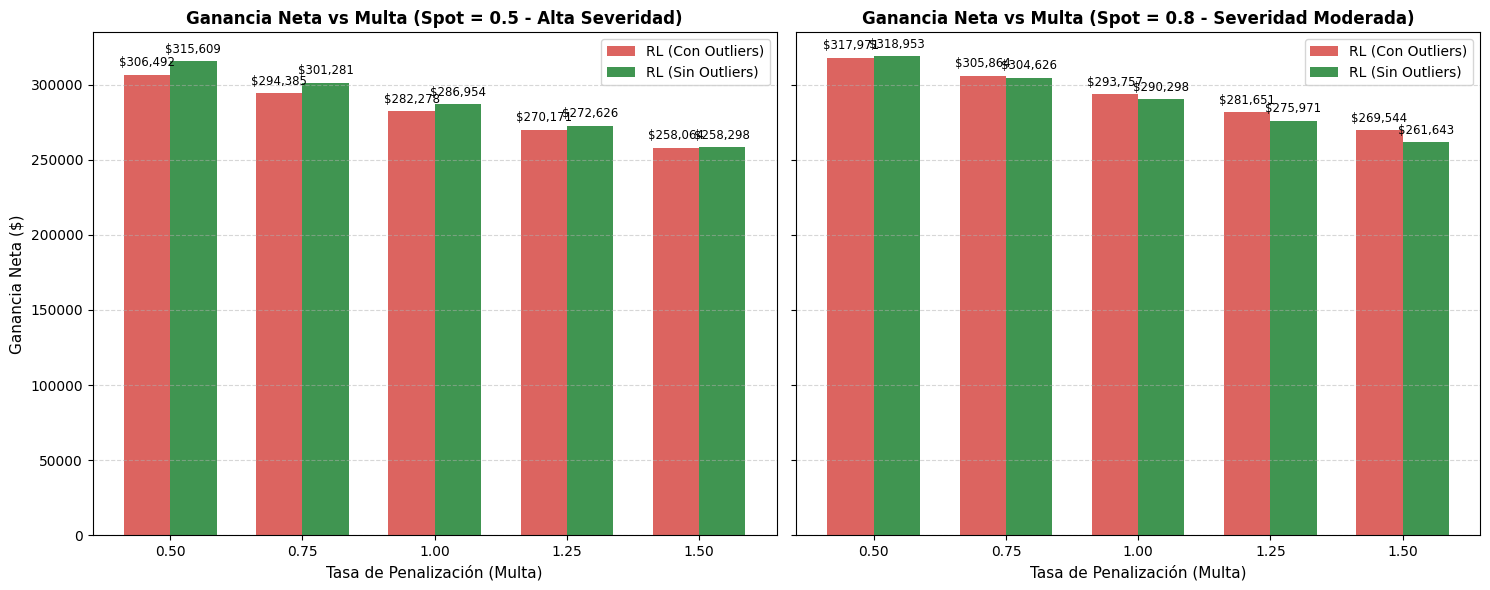

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==============================================================================
# BARRIDO DISCRETO DE MULTAS (SELECCIÓN PARA GRÁFICO DE BARRAS)
# ==============================================================================
# Seleccionamos tasas representativas para que las barras no se amontonen
tasas_sweep = [0.5, 0.75, 1.0, 1.25, 1.5]

# 1. Generación de datos para Spot = 0.5
df_sweep_05 = pd.concat(
    [evaluar_balance_economico(tm, 0.5) for tm in tasas_sweep],
    ignore_index=True,
)
df_sweep_05_lr = df_sweep_05[df_sweep_05['Modelo'] == 'Regresión Lineal']

# 2. Generación de datos para Spot = 0.8
df_sweep_08 = pd.concat(
    [evaluar_balance_economico(tm, 0.8) for tm in tasas_sweep],
    ignore_index=True,
)
df_sweep_08_lr = df_sweep_08[df_sweep_08['Modelo'] == 'Regresión Lineal']

# ==============================================================================
# GRÁFICAS COMPARATIVAS DE BARRAS (MISMA ESCALA EN EJE Y)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

x_pos = np.arange(len(tasas_sweep))
bar_width = 0.35
x_labels = [f'{t:.2f}' for t in tasas_sweep]


def trazar_barras(ax, df_data, titulo):
  df_con = df_data[df_data['Enfoque'] == 'Con Outliers']
  df_sin = df_data[df_data['Enfoque'] == 'Sin Outliers']

  rects1 = ax.bar(
      x_pos - bar_width / 2,
      df_con['Ganancia_Neta_$'],
      width=bar_width,
      label='RL (Con Outliers)',
      color='#d9534f',
      alpha=0.9,
  )
  rects2 = ax.bar(
      x_pos + bar_width / 2,
      df_sin['Ganancia_Neta_$'],
      width=bar_width,
      label='RL (Sin Outliers)',
      color='#2b8a3e',
      alpha=0.9,
  )

  # Etiquetas numéricas sobre cada barra
  for rect in list(rects1) + list(rects2):
    altura = rect.get_height()
    ax.annotate(
        f'${altura:,.0f}',
        xy=(rect.get_x() + rect.get_width() / 2, altura),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=8.5,
    )

  ax.set_title(titulo, fontweight='bold', fontsize=12)
  ax.set_xlabel('Tasa de Penalización (Multa)', fontsize=11)
  ax.set_xticks(x_pos)
  ax.set_xticklabels(x_labels)
  ax.legend(fontsize=10, loc='upper right')
  ax.grid(True, linestyle='--', alpha=0.5, axis='y')


# Gráfica 1: Spot = 0.5
ax1.set_ylabel('Ganancia Neta ($)', fontsize=11)
trazar_barras(
    ax1, df_sweep_05_lr, 'Ganancia Neta vs Multa (Spot = 0.5 - Alta Severidad)'
)

# Gráfica 2: Spot = 0.8
trazar_barras(
    ax2,
    df_sweep_08_lr,
    'Ganancia Neta vs Multa (Spot = 0.8 - Severidad Moderada)',
)

plt.tight_layout()
plt.savefig('c3_grafico_barras_spot.png', dpi=300, bbox_inches='tight')
plt.show()

## Menos datos

In [ ]:
# ==========================================
# 1. HISTÓRICO ULTRA CORTO (2 AÑOS, 20 HECTÁREAS)
# ==========================================
n_hectareas = 20
anos_historicos = 2
ciclos_por_ano = 2
total_ciclos_hist = anos_historicos * ciclos_por_ano

np.random.seed(42)
cantidad_x_hectarea = np.random.uniform(100, 150, size=n_hectareas)

registros_cortos = []
for i in range(n_hectareas):
    x_ideal = cantidad_x_hectarea[i]
    for ciclo in range(total_ciclos_hist):
        factor_variacion = np.random.uniform(0.5, 0.8)
        x_s = x_ideal * factor_variacion

        ruido = np.random.normal(loc=10, scale=5)
        y_s = 15 * x_s
        y_s = (1 + ruido / 100) * y_s

        # Mantenemos el 10% de riesgo de crisis real
        if np.random.random() < 0.10:
            y_s = y_s * np.random.uniform(0.0, 0.5)

        registros_cortos.append({
            "Semillas_Plantadas_x_kg": x_s,
            "Produccion_Obtenida_y_kg": y_s
        })

df_corto = pd.DataFrame(registros_cortos)

# Separación Train/Test (Pocos datos: solo 80 filas en total)
X = df_corto[['Semillas_Plantadas_x_kg']]
y = df_corto['Produccion_Obtenida_y_kg']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==========================================
# 2. ENTRENAMIENTO CON ESCASEZ DE DATOS
# ==========================================
modelos = {
    "Regresión Lineal": LinearRegression(),
    "MLP (Red Neuronal)": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=4000, random_state=42)),
    "Random Forest": RandomForestRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42)
}

# Evaluamos SOLO el RMSE en el conjunto de pruebas corto
print("### FASE 1: RENDIMIENTO EN EL LABORATORIO (TEST SET) ###")
resultados_rmse = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    y_pred_test = modelo.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    resultados_rmse.append({"Modelo": nombre, "RMSE (Test)": round(rmse, 2)})

print(pd.DataFrame(resultados_rmse).to_markdown(index=False))
print("\n" + "="*70 + "\n")

### FASE 1: RENDIMIENTO EN EL LABORATORIO (TEST SET) ###
| Modelo             |   RMSE (Test) |
|:-------------------|--------------:|
| Regresión Lineal   |        301.48 |
| MLP (Red Neuronal) |       1367.1  |
| Random Forest      |        185.38 |
| XGBoost            |        233.32 |




/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (4000) reached and the optimization hasn't converged yet.
  warnings.warn(


### FASE 2: EL IMPACTO REAL EN LOS CONTRATOS Z ###
| Modelo             |   Contrato Z_d (kg) |   Penalización p (%) |   Costo Oportunidad (%) |
|:-------------------|--------------------:|---------------------:|------------------------:|
| Regresión Lineal   |               45200 |                 9.91 |                   16.76 |
| MLP (Red Neuronal) |                   0 |                 0    |                    0    |
| Random Forest      |               46700 |                 9.4  |                   12.83 |
| XGBoost            |               44700 |                 8.89 |                   16.94 |


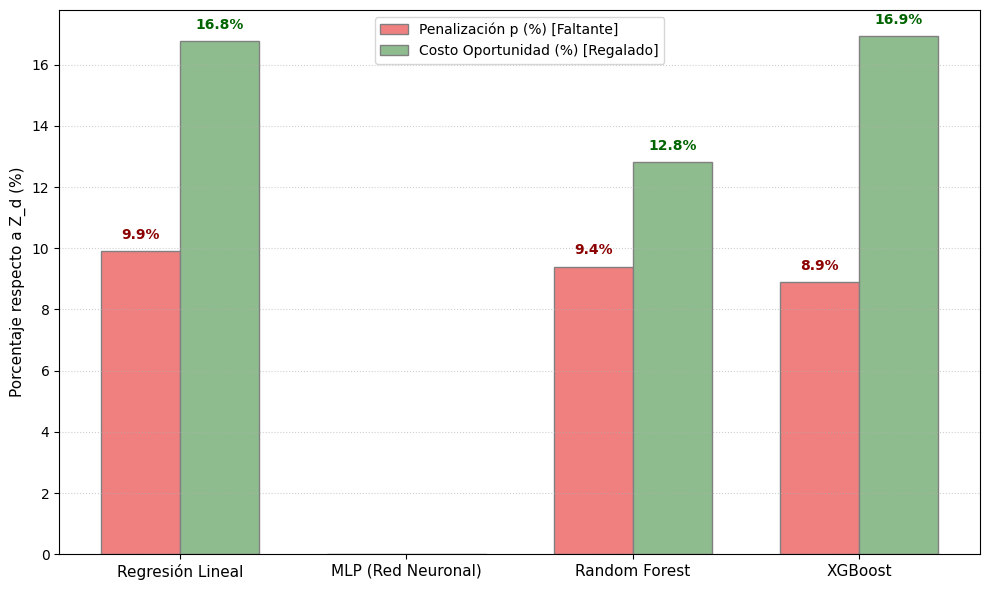

In [ ]:
# ==========================================
# 3. SIMULACIÓN DE CONTRATOS EN EL MUNDO REAL (1 AÑO NUEVO)
# ==========================================
# Generamos un año nuevo de operación bajo las mismas condiciones para ver cómo sufren
np.random.seed(2026)
registros_futuros = []

for i in range(n_hectareas):
    x_ideal = cantidad_x_hectarea[i]
    for semestre in range(2):
        factor_variacion = np.random.uniform(0.5, 0.8)
        x_s = x_ideal * factor_variacion

        ruido = np.random.normal(loc=10, scale=5)
        y_real = 15 * x_s
        y_real = (1 + ruido / 100) * y_real

        if np.random.random() < 0.10:
            y_real = y_real * np.random.uniform(0.0, 0.5)

        registros_futuros.append({
            "Semillas_Plantadas_x_kg": x_s,
            "Produccion_Real_y_kg": y_real
        })

df_futuro = pd.DataFrame(registros_futuros)
X_futuro = df_futuro[['Semillas_Plantadas_x_kg']]

resumen_negocio = []
for nombre, modelo in modelos.items():
    y_pred_futuro = modelo.predict(X_futuro)
    Z_comprometido = (y_pred_futuro // 100) * 100  # Truncado a cientos cerrados

    df_eval = df_futuro.copy()
    df_eval['Contrato_Z'] = Z_comprometido
    df_eval['Sobrante_kg'] = np.maximum(0, df_eval['Produccion_Real_y_kg'] - df_eval['Contrato_Z'])
    df_eval['Faltante_kg'] = np.maximum(0, df_eval['Contrato_Z'] - df_eval['Produccion_Real_y_kg'])

    total_z = df_eval['Contrato_Z'].sum()
    p_penalizacion = (df_eval['Faltante_kg'].sum() / total_z) * 100 if total_z > 0 else 0
    p_oportunidad = (df_eval['Sobrante_kg'].sum() / total_z) * 100 if total_z > 0 else 0

    resumen_negocio.append({
        "Modelo": nombre,
        "Contrato Z_d (kg)": round(total_z, 1),
        "Penalización p (%)": round(p_penalizacion, 2),
        "Costo Oportunidad (%)": round(p_oportunidad, 2)
    })

df_resumen_negocio = pd.DataFrame(resumen_negocio)
print("### FASE 2: EL IMPACTO REAL EN LOS CONTRATOS Z ###")
print(df_resumen_negocio.to_markdown(index=False))

# ==========================================
# 4. GRÁFICO COMPARATIVO DE CONTRATOS
# ==========================================
fig, ax = plt.subplots(figsize=(10, 6))
x_indices = np.arange(len(df_resumen_negocio))
ancho_barra = 0.35

b1 = ax.bar(x_indices - ancho_barra/2, df_resumen_negocio['Penalización p (%)'], ancho_barra, label='Penalización p (%) [Faltante]', color='lightcoral', edgecolor='grey')
b2 = ax.bar(x_indices + ancho_barra/2, df_resumen_negocio['Costo Oportunidad (%)'], ancho_barra, label='Costo Oportunidad (%) [Regalado]', color='darkseagreen', edgecolor='grey')

#ax.set_title('Rendimiento Contractual con Datos Escasos (Solo 2 Años de Histórico)', fontsize=13, fontweight='bold')
ax.set_ylabel('Porcentaje respecto a Z_d (%)', fontsize=11)
ax.set_xticks(x_indices)
ax.set_xticklabels(df_resumen_negocio['Modelo'], fontsize=11)
ax.legend()
ax.grid(axis='y', linestyle=':', alpha=0.6)

def agregar_etiquetas(barras, color_texto):
    for barra in barras:
        yval = barra.get_height()
        if yval > 0:
            ax.text(barra.get_x() + barra.get_width()/2, yval + 0.3, f"{yval:.1f}%", ha='center', va='bottom', fontsize=10, fontweight='bold', color=color_texto)

agregar_etiquetas(b1, 'darkred')
agregar_etiquetas(b2, 'darkgreen')
plt.tight_layout()
plt.show()

In [ ]:
# 1. Extraer el modelo lineal entrenado del diccionario
reg_lineal = modelos["Regresión Lineal"]

# 2. Obtener los componentes de la línea recta (Y = mX + b)
m = reg_lineal.coef_[0]
b = reg_lineal.intercept_

# 3. Mostrar la ecuación formateada
print("### LA ECUACIÓN DE TU REGRESIÓN LINEAL ###")
print(f"Y = {m:.4f} * X + {b:.4f}")
print("\nSignificado para el negocio:")
print(f" -> Por cada 1 kg de semilla extra, el modelo predice que cosecharás {m:.2f} kg adicionales.")
print(f" -> Si sembraras 0 kg de semillas, el modelo estima una base fija de {b:.2f} kg.")

### LA ECUACIÓN DE TU REGRESIÓN LINEAL ###
Y = 11.7385 * X + 219.3523

Significado para el negocio:
 -> Por cada 1 kg de semilla extra, el modelo predice que cosecharás 11.74 kg adicionales.
 -> Si sembraras 0 kg de semillas, el modelo estima una base fija de 219.35 kg.
